# CNN Model: American Sign Language (ASL) Recognition
**Course:** Deep Learning | **Midterm Project**

---

## 1. Problem Definition

American Sign Language (ASL) is the primary language for the Deaf and hard-of-hearing community. Automatic recognition of hand gestures can bridge the communication gap between signers and non-signers, enabling real-time translation tools and accessibility apps.

**Problem:** Given a 28x28 grayscale image of a hand gesture, classify it into one of 24 ASL alphabet letters (excluding J and Z, which require motion).

**Type:** Multi-class Image Classification (24 classes)

**Business Value:** Powers assistive communication tools, sign language learning platforms, and accessibility applications for the Deaf community.

## 2. Dataset Description

- **Dataset Name:** Sign Language MNIST
- **Source:** [Kaggle - Sign Language MNIST](https://www.kaggle.com/datasets/datamunge/sign-language-mnist)
- **Format:** CSV (pixel values, MNIST-style)
- **Training samples:** 27,455 | **Test samples:** 7,172
- **Image size:** 28 x 28 pixels, grayscale
- **Classes:** 24 (A-Y, excluding J=9 and Z=25 which involve motion)

Each row: first column = label, followed by 784 pixel values (28x28 flattened).

## 3. Proposed Solution

A Convolutional Neural Network (CNN) is proposed. CNNs automatically learn spatial hierarchies of features from images:

- **Early layers** detect low-level features (edges, curves)
- **Deeper layers** detect high-level patterns (finger positions, hand shapes)
- **Fully connected layers** perform final classification

Batch Normalization, MaxPooling, and Dropout improve training stability and prevent overfitting.

## 4. Data Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelBinarizer
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import joblib

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

train_df = pd.read_csv('/content/drive/MyDrive/sign_mnist_train.csv')
test_df  = pd.read_csv('/content/drive/MyDrive/sign_mnist_test.csv')

print('Train shape:', train_df.shape)
print('Test shape:', test_df.shape)

Mounted at /content/drive
Train shape: (27455, 785)
Test shape: (7172, 785)


In [3]:
# Separate labels and pixel values
y_train = train_df['label'].values
X_train = train_df.drop('label', axis=1).values.reshape(-1, 28, 28, 1).astype('float32') / 255.0

y_test = test_df['label'].values
X_test = test_df.drop('label', axis=1).values.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print('X_train shape:', X_train.shape)
print('Unique labels:', np.unique(y_train))

X_train shape: (27455, 28, 28, 1)
Unique labels: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


In [4]:
# Build label map (skip J=9 and Z=25)
letters = [chr(i) for i in range(65, 91) if chr(i) not in ['J', 'Z']]
unique_labels = sorted(np.unique(y_train))
label_map = {v: letters[i] for i, v in enumerate(unique_labels)}
print('Label map:', label_map)

Label map: {np.int64(0): 'A', np.int64(1): 'B', np.int64(2): 'C', np.int64(3): 'D', np.int64(4): 'E', np.int64(5): 'F', np.int64(6): 'G', np.int64(7): 'H', np.int64(8): 'I', np.int64(10): 'K', np.int64(11): 'L', np.int64(12): 'M', np.int64(13): 'N', np.int64(14): 'O', np.int64(15): 'P', np.int64(16): 'Q', np.int64(17): 'R', np.int64(18): 'S', np.int64(19): 'T', np.int64(20): 'U', np.int64(21): 'V', np.int64(22): 'W', np.int64(23): 'X', np.int64(24): 'Y'}


In [5]:
# One-hot encode labels
lb = LabelBinarizer()
y_train_enc = lb.fit_transform(y_train)
y_test_enc  = lb.transform(y_test)
num_classes = y_train_enc.shape[1]
print('Number of classes:', num_classes)

Number of classes: 24


In [6]:
# Split the original training data into training and validation sets
# Keep the original test set separate for final evaluation only.
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train_enc,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training images:", X_train_new.shape[0])
print("Validation images:", X_val.shape[0])
print("Test images:", X_test.shape[0])

Training images: 21964
Validation images: 5491
Test images: 7172


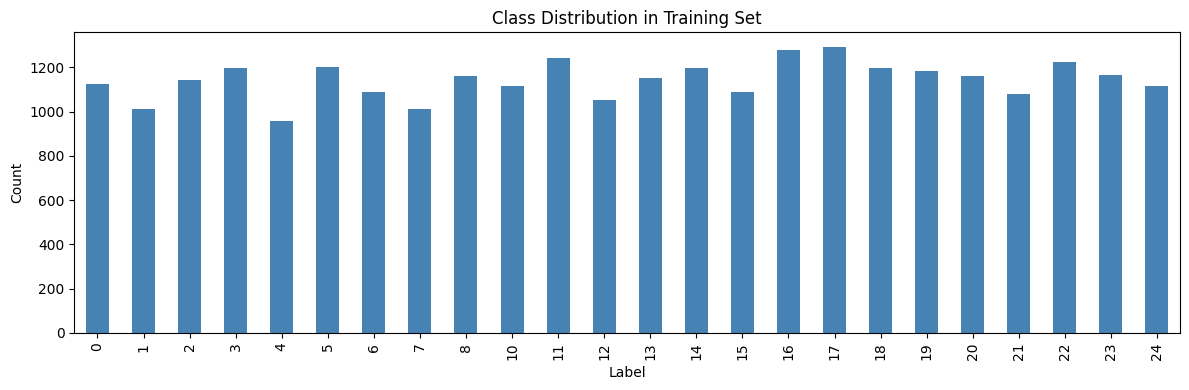

In [7]:
# Visualize class distribution
plt.figure(figsize=(12, 4))
pd.Series(y_train).value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Class Distribution in Training Set')
plt.xlabel('Label'); plt.ylabel('Count'); plt.tight_layout(); plt.show()

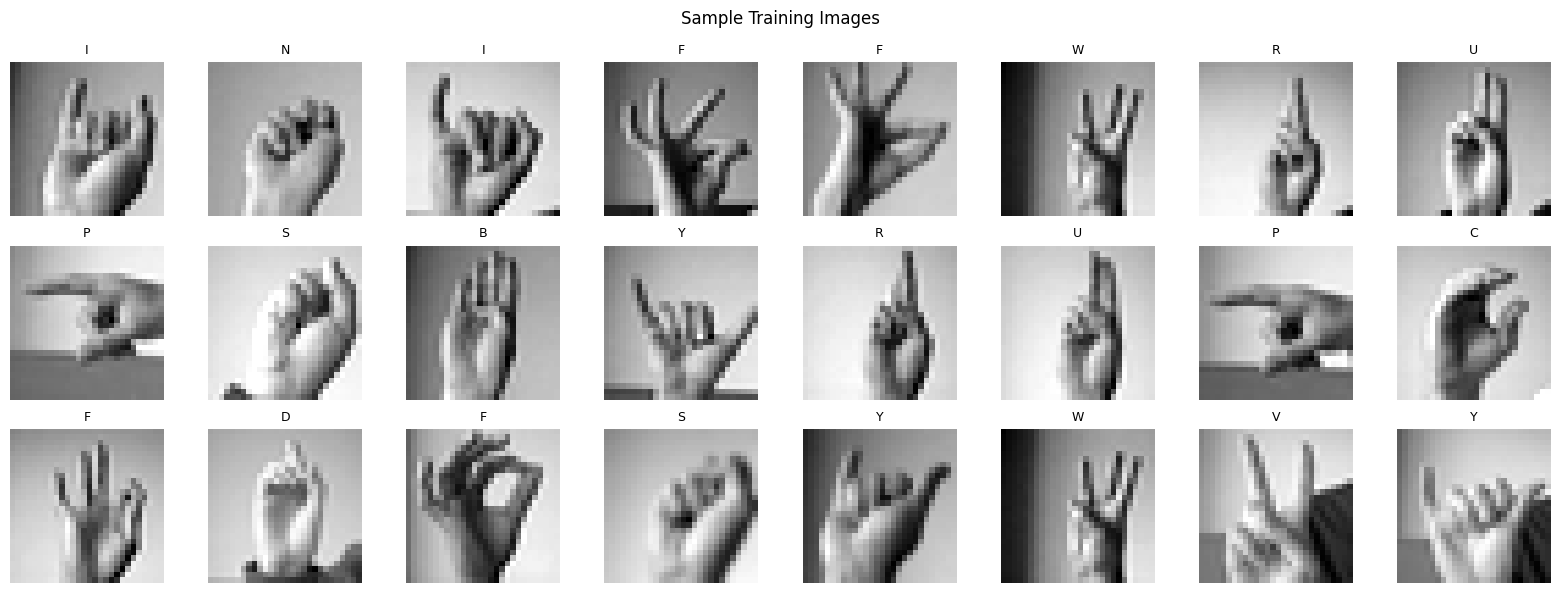

In [8]:
# Sample images
fig, axes = plt.subplots(3, 8, figsize=(16, 6))
for i, ax in enumerate(axes.flatten()):
    idx = np.random.randint(0, len(X_train))
    ax.imshow(X_train[idx].reshape(28, 28), cmap='gray')
    ax.set_title(label_map.get(y_train[idx], str(y_train[idx])), fontsize=9)
    ax.axis('off')
plt.suptitle('Sample Training Images')
plt.tight_layout(); plt.show()

## 5. Model Architecture

| Block | Layer | Details | Output |
|---|---|---|---|
| Block 1 | Conv2D (32 filters) + BN | 3x3, ReLU | 28x28x32 |
| Block 1 | Conv2D (32 filters) + BN | 3x3, ReLU | 28x28x32 |
| Block 1 | MaxPooling + Dropout (25%) | 2x2 | 14x14x32 |
| Block 2 | Conv2D (64 filters) + BN | 3x3, ReLU | 14x14x64 |
| Block 2 | Conv2D (64 filters) + BN | 3x3, ReLU | 14x14x64 |
| Block 2 | MaxPooling + Dropout (25%) | 2x2 | 7x7x64 |
| Head | Flatten → Dense(512) + BN + Dropout(50%) | ReLU | 512 |
| Output | Dense(24, Softmax) | 24 classes | 24 |

In [9]:
def build_cnn(input_shape, num_classes):
    model = keras.Sequential([
        # Block 1
        layers.Conv2D(32, (3,3), padding='same', activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3,3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),
        # Block 2
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),
        # Classification head
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

model = build_cnn((28, 28, 1), num_classes)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,606,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │        12,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,686,264 (6.43 MB)

 Trainable params: 1,684,856 (6.43 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_accuracy', patience=8, restore_best_weights=True
)
lr_sched = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
)

history = model.fit(
    X_train_new, y_train_new,
    epochs=30, batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, lr_sched],
    verbose=1
)

Epoch 1/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 68s 191ms/step - accuracy: 0.8768 - loss: 0.4332 - val_accuracy: 0.2398 - val_loss: 2.5284 - learning_rate: 0.0010
Epoch 2/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 64s 186ms/step - accuracy: 0.9944 - loss: 0.0273 - val_accuracy: 1.0000 - val_loss: 0.0021 - learning_rate: 0.0010
Epoch 3/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 64s 187ms/step - accuracy: 0.9986 - loss: 0.0099 - val_accuracy: 1.0000 - val_loss: 8.7788e-04 - learning_rate: 0.0010
Epoch 4/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 66s 191ms/step - accuracy: 0.9980 - loss: 0.0101 - val_accuracy: 0.9996 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 5/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 81s 189ms/step - accuracy: 0.9984 - loss: 0.0072 - val_accuracy: 1.0000 - val_loss: 1.2982e-04 - learning_rate: 0.0010
Epoch 6/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 64s 186ms/step - accuracy: 0.9993 - loss: 0.0042 - val_accuracy: 0.9991 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 7/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 83s 188ms/step - accur

## 6. Training Results and Evaluation

**Data split note:** The original training dataset is divided into training and validation subsets. The separate test dataset is kept untouched during training and is used only for final evaluation.


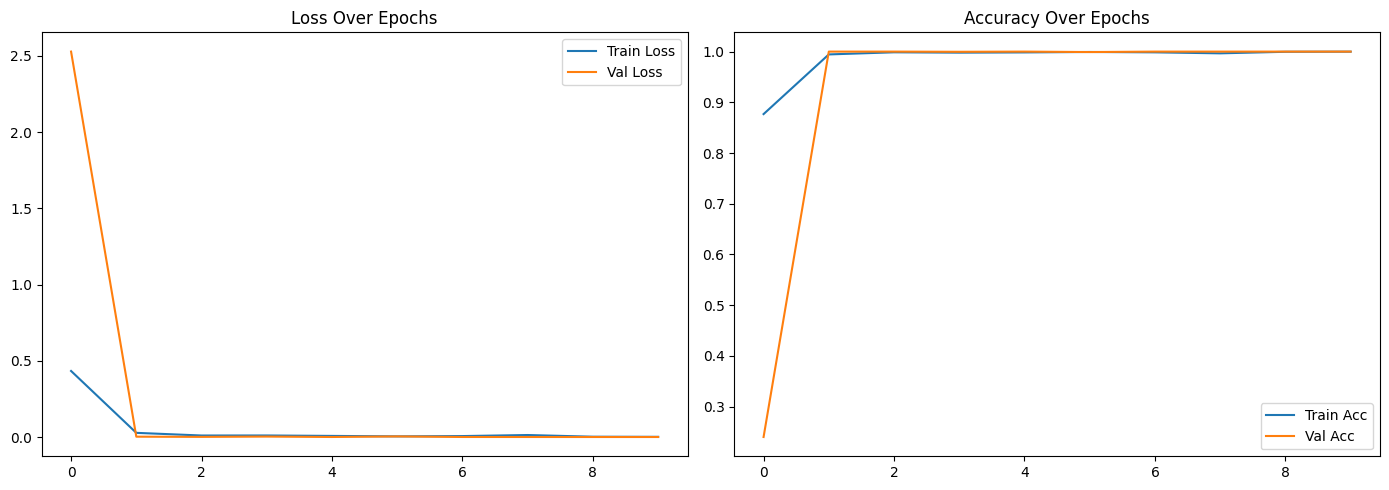

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss Over Epochs'); axes[0].legend()
axes[1].plot(history.history['accuracy'], label='Train Acc')
axes[1].plot(history.history['val_accuracy'], label='Val Acc')
axes[1].set_title('Accuracy Over Epochs'); axes[1].legend()
plt.tight_layout(); plt.show()

In [12]:
test_loss, test_acc = model.evaluate(X_test, y_test_enc, verbose=0)
print(f'Test Accuracy: {test_acc:.4f}')
print(f'Test Loss:     {test_loss:.4f}')

Test Accuracy: 0.9485
Test Loss:     0.1696


In [13]:
y_pred_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_enc, axis=1)

target_names = [label_map[l] for l in unique_labels]
print(classification_report(y_true, y_pred, target_names=target_names))

              precision    recall  f1-score   support

           A       0.89      1.00      0.94       331
           B       1.00      1.00      1.00       432
           C       1.00      1.00      1.00       310
           D       1.00      1.00      1.00       245
           E       1.00      1.00      1.00       498
           F       1.00      1.00      1.00       247
           G       0.89      0.94      0.92       348
           H       0.92      0.91      0.91       436
           I       1.00      0.99      0.99       288
           K       1.00      0.90      0.95       331
           L       0.96      1.00      0.98       209
           M       0.93      0.95      0.94       394
           N       0.91      0.71      0.80       291
           O       1.00      0.91      0.96       246
           P       1.00      1.00      1.00       347
           Q       1.00      1.00      1.00       164
           R       0.60      1.00      0.75       144
           S       0.92    

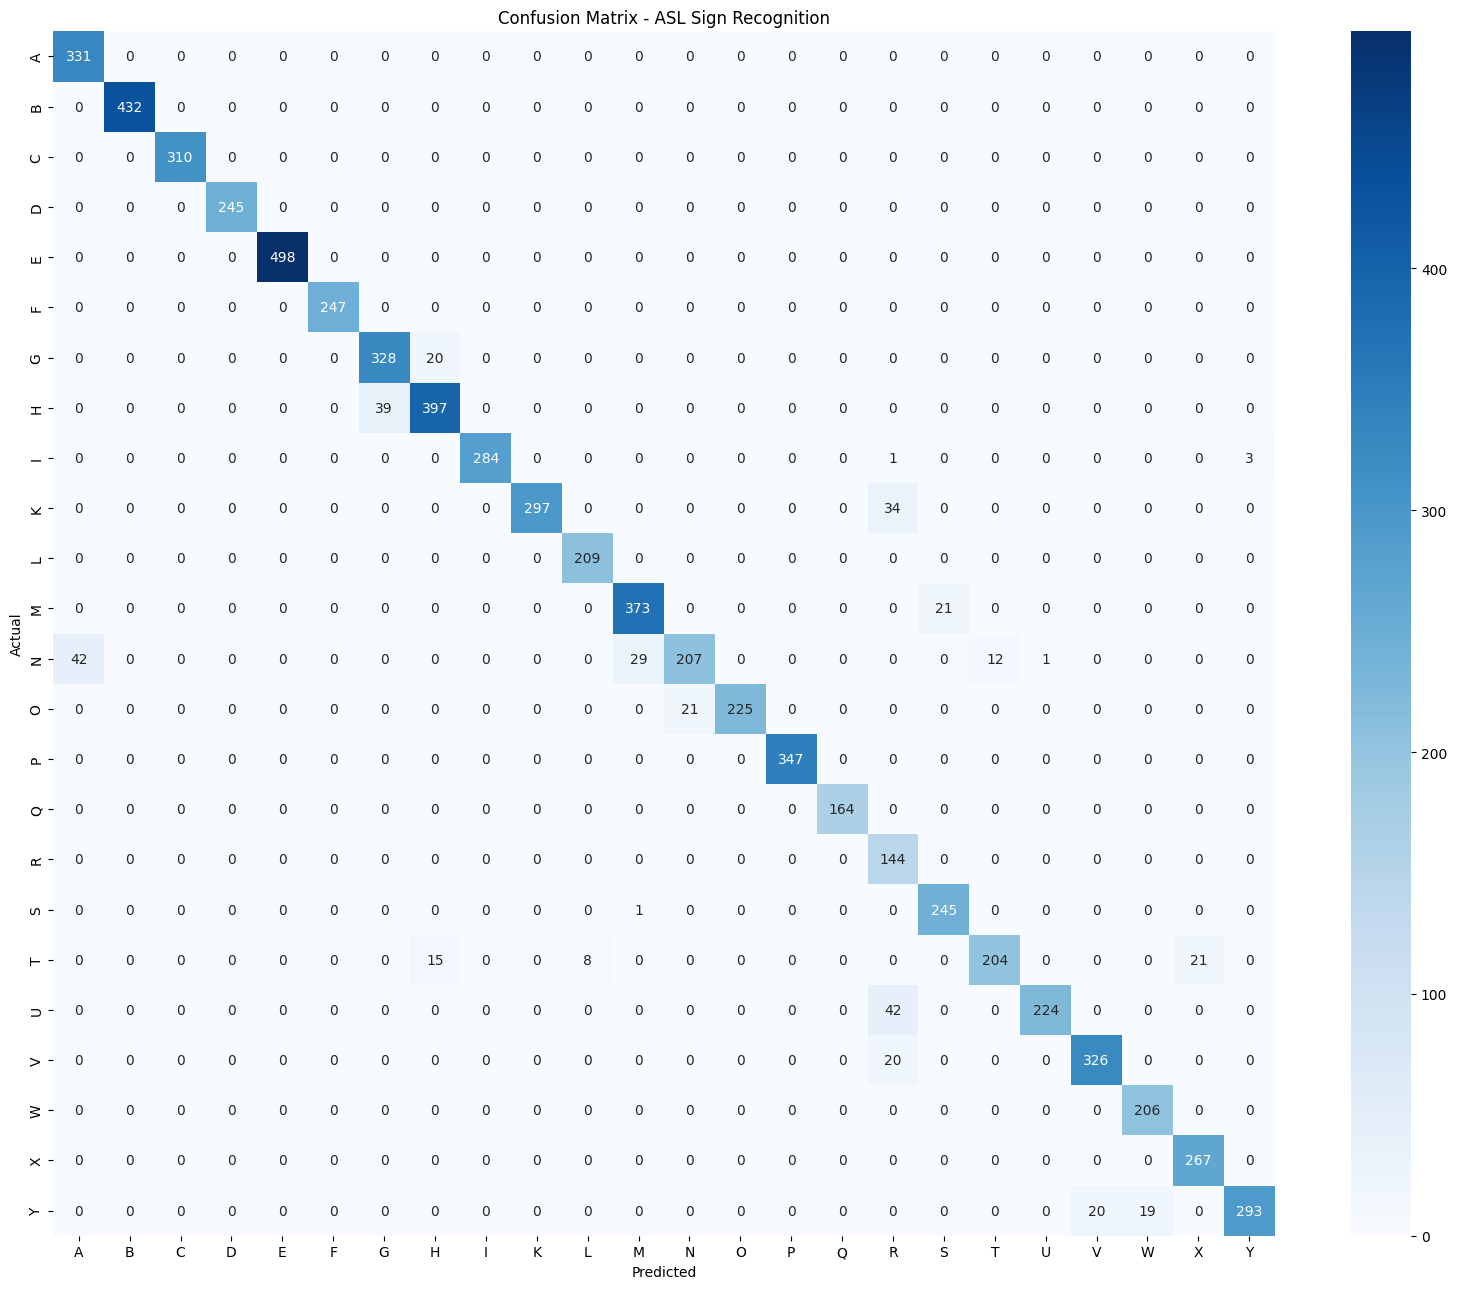

In [14]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(16, 13))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - ASL Sign Recognition')
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()

## 6b. Inference Step

The inference step shows the trained CNN making predictions on **new, unseen images** — simulating real-world use.

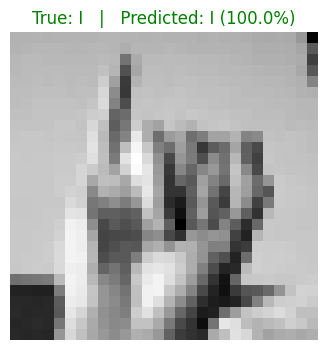

       INFERENCE RESULT
True Label   : I
Predicted    : I
Confidence   : 100.00%
Correct      : True


In [15]:
# --- INFERENCE ON A SINGLE IMAGE ---
# Take one test image the model has never been trained on

sample_idx = 42  # Change this to try different images
sample_image = X_test[sample_idx:sample_idx+1]  # Shape: (1, 28, 28, 1)
true_label   = label_map[unique_labels[y_true[sample_idx]]]

# Predict
pred_probs  = model.predict(sample_image, verbose=0)[0]
pred_idx    = np.argmax(pred_probs)
pred_label  = label_map[unique_labels[pred_idx]]
confidence  = pred_probs[pred_idx]

# Display
plt.figure(figsize=(4, 4))
plt.imshow(sample_image.reshape(28, 28), cmap='gray')
plt.title(f'True: {true_label}   |   Predicted: {pred_label} ({confidence*100:.1f}%)',
          color='green' if pred_label == true_label else 'red', fontsize=12)
plt.axis('off'); plt.show()

print('=' * 40)
print('       INFERENCE RESULT')
print('=' * 40)
print(f'True Label   : {true_label}')
print(f'Predicted    : {pred_label}')
print(f'Confidence   : {confidence*100:.2f}%')
print(f'Correct      : {pred_label == true_label}')
print('=' * 40)

In [16]:
# --- TOP-3 PREDICTIONS (shows model confidence distribution) ---
top3_indices = np.argsort(pred_probs)[::-1][:3]
print('Top-3 Predictions:')
for rank, idx in enumerate(top3_indices, 1):
    letter = label_map[unique_labels[idx]]
    prob   = pred_probs[idx]
    print(f'  {rank}. Letter {letter}: {prob*100:.2f}%')

Top-3 Predictions:
  1. Letter I: 100.00%
  2. Letter V: 0.00%
  3. Letter T: 0.00%


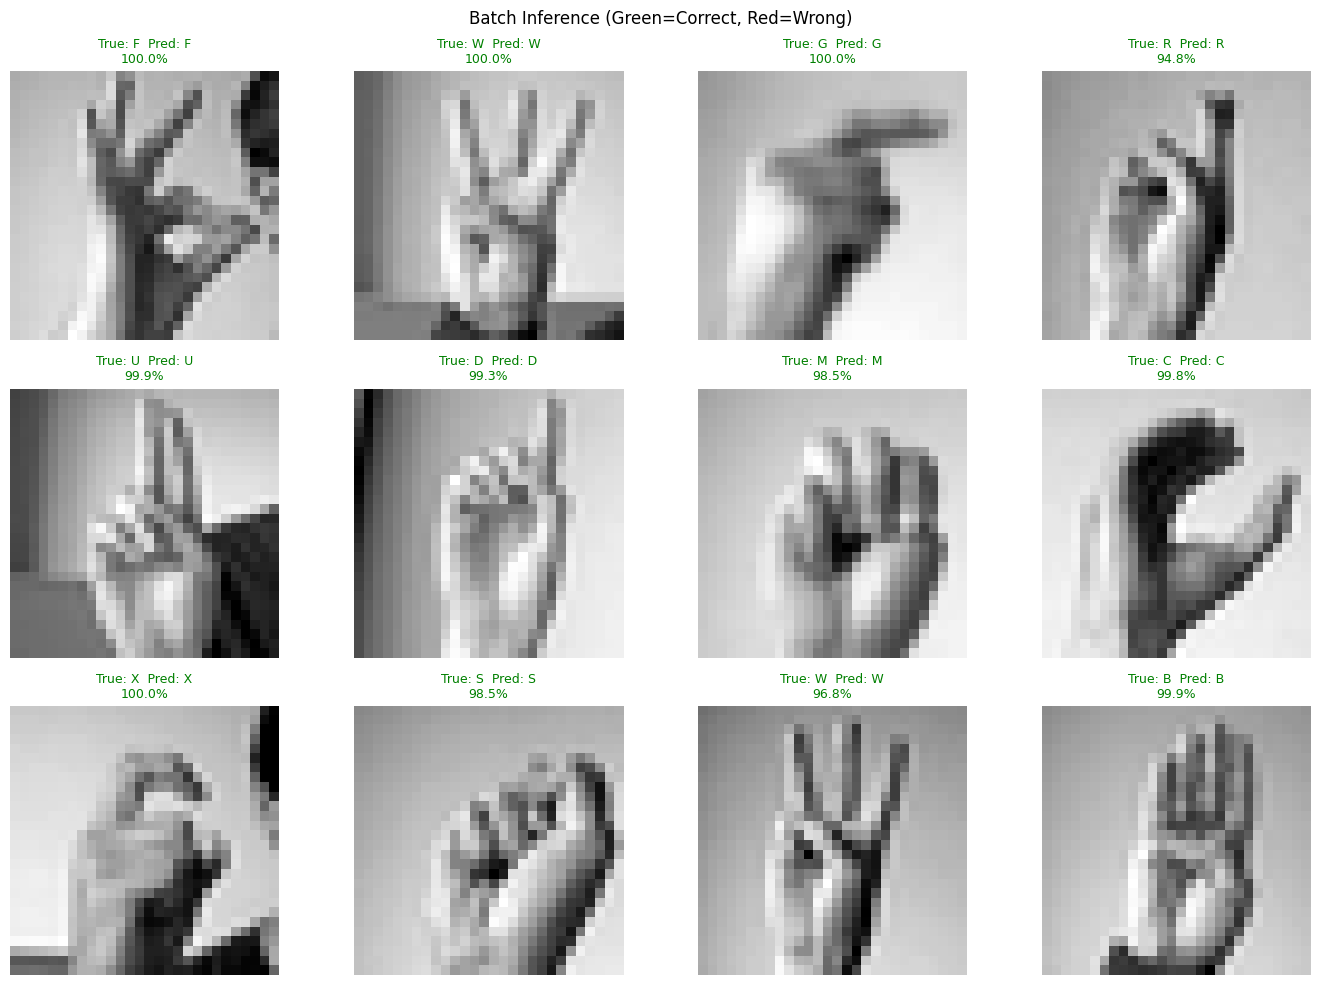

In [17]:
# --- BATCH INFERENCE: 12 random test images ---
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
batch_indices = np.random.choice(len(X_test), 12, replace=False)

for ax, idx in zip(axes.flatten(), batch_indices):
    img   = X_test[idx:idx+1]
    probs = model.predict(img, verbose=0)[0]
    pred  = label_map[unique_labels[np.argmax(probs)]]
    true  = label_map[unique_labels[y_true[idx]]]
    conf  = probs.max()

    ax.imshow(img.reshape(28, 28), cmap='gray')
    color = 'green' if pred == true else 'red'
    ax.set_title(f'True: {true}  Pred: {pred}\n{conf*100:.1f}%', color=color, fontsize=9)
    ax.axis('off')

plt.suptitle('Batch Inference (Green=Correct, Red=Wrong)', fontsize=12)
plt.tight_layout(); plt.show()

## 7. Save Model in .joblib Format

In [18]:
# Save model + label map + binarizer together
joblib.dump({
    'model'        : model,
    'label_map'    : label_map,
    'unique_labels': unique_labels,
    'lb'           : lb
}, '/content/drive/MyDrive/cnn_sign_model.joblib')

print('Model saved to Google Drive as cnn_sign_model.joblib')

Model saved to Google Drive as cnn_sign_model.joblib


In [19]:
# Load and verify
saved = joblib.load('/content/drive/MyDrive/cnn_sign_model.joblib')
loaded_model   = saved['model']
loaded_lmap    = saved['label_map']
loaded_ulabels = saved['unique_labels']

# Re-run inference with loaded model
verify_probs  = loaded_model.predict(X_test[42:43], verbose=0)[0]
verify_pred   = loaded_lmap[loaded_ulabels[np.argmax(verify_probs)]]
print(f'Loaded model prediction for image 42: {verify_pred}')
print('Model loaded and verified successfully.')

Loaded model prediction for image 42: I
Model loaded and verified successfully.


## 8. Conclusion

This project developed a CNN to classify American Sign Language alphabet gestures from 28x28 grayscale images:

- **Dataset:** 27,455 training and 7,172 test images across 24 ASL classes
- **Preprocessing:** Pixel normalization to [0, 1], reshape to (28, 28, 1), one-hot encoding
- **Architecture:** Dual-block CNN with BatchNormalization and Dropout for robust feature extraction
- **Callbacks:** EarlyStopping and ReduceLROnPlateau for efficient, stable training
- **Inference:** Demonstrated on single image (with top-3 confidence) and batch of 12 images
- **Saved:** Model + label metadata packaged in `.joblib` for deployment

The CNN's convolutional layers far outperform traditional ML on image tasks. Future improvements: transfer learning with MobileNetV2, higher-resolution inputs, or real-time webcam inference.